# Midterm EDA: did the 2023 electricity price shock speed up rooftop solar?

This notebook goes **from the raw public files in `data/` to every number and figure on our slides** (where each file comes from: `README.md`). Read it top to bottom: each section follows one step of the course brief and names its slide. Run it with *Kernel → Restart & Run All* (under a minute).

| Section | Brief step | Slides |
|---|---|---|
| 1. Ingredients: from raw files to clean variables | 1–2. Variables, cleaning | 2, 5, 6 |
| 2. Sample and summary statistics | 2. Select the sample | 6, 7 |
| 3. Univariate analysis (Y, Z, X) | 3. Taste each ingredient | 8–11 |
| 4. Bivariate analysis | 4. Cook them together | 12–14, backup |
| 5. Causality issues | 5. Taste the recipe | 15, 16 |

- **Y (outcome):** new PV installations per commune and year.
- **X (main explanatory):** the 2023 increase in the household electricity tariff, ct/kWh ("the shock").
- **Z (heterogeneity):** owner-occupier share, the share of dwellings lived in by their owner (tenants usually cannot install panels themselves).

In [1]:
import json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm                          # only for the confidence intervals in section 4
from shapely import STRtree, points, get_parts        # to find which commune each solar plant is in
from shapely.geometry import shape
from shapely.ops import unary_union

BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9aa5b1"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e5e8eb"})

## 1. Ingredients: from raw files to clean variables (slides 5 and 6)

### 1a. One commune code for every source
Swiss communes merge every year, and each source uses the commune numbers of its own year. The FSO mutation register ([official commune register](https://www.bfs.admin.ch/bfs/de/home/grundlagen/agvch.html)) lists every merger since 2010 (old number → new number). We follow these links until we reach the commune that exists in 2026, and put **every source on 2026 communes**.

In [3]:
mutations = pd.read_csv("data/bfs_commune_mutations.csv")
mutations = mutations[mutations.InitialCode != mutations.TerminalCode]     # keep real changes of number
successor = dict(zip(mutations.InitialCode, mutations.TerminalCode))

def to_2026(code):
    while code in successor:                   # follow chains of mergers: A -> B (2015) -> C (2021)
        code = successor[code]
    return code

print("example: commune 343 became", to_2026(343))

example: commune 343 became 329


### 1b. Population and canton (FSO STATPOP, [table px-x-0102010000_101](https://www.bfs.admin.ch/asset/de/px-x-0102010000_101))
One line per canton (`- Zürich`), district (`>> ...`) and commune (`......0001 Aeugst am Albis`) and year. We keep the commune lines.

In [5]:
raw = pd.read_csv("data/bfs_population.csv", encoding="latin1")
raw.columns = ["year", "place", "type", "nationality", "sex", "pop"]
rows, canton = [], None
for place, year, n in zip(raw.place, raw.year, raw["pop"]):
    if place.startswith("- "):
        canton = place[2:]                                          # canton header line
    elif place.startswith("......"):
        rows.append((to_2026(int(place[6:10])), canton, year, n))   # commune line
pop = pd.DataFrame(rows, columns=["bfs", "canton", "year", "pop"])
canton_of = pop.groupby("bfs").canton.last()
pop = pop.groupby(["bfs", "year"])["pop"].sum().unstack()          # merged communes are summed; one column per year
print("communes in 2026:", len(pop))

communes in 2026: 2110


### 1c. X: the 2023 tariff increase (ElCom, [electricity price per grid operator](https://opendata.swiss/de/dataset/strompreis-per-stromnetzbetreiber))
One tariff per commune × operator × year and consumption profile. We keep profile **H4** (ElCom's standard household: 5-room flat, 4,500 kWh/year), take the **total price** in ct/kWh, average it over the operators serving each commune, and compute **X = 2023 − 2022**. The 2023 tariffs were published in August 2022. We also keep the commune's main operator: the one listed most often in 2023 (if two tie, the lower ElCom number).

In [7]:
elcom = pd.read_csv("data/elcom_tariffs_H2_H4_H7.csv")
h4 = elcom[elcom.category == "H4"].copy()
h4["bfs"] = h4.municipality.map(to_2026)
tariff = h4.groupby(["bfs", "period"]).total.mean().unstack()          # one column per year, ct/kWh
energy = h4.groupby(["bfs", "period"]).energy.mean().unstack()         # energy part of the price
main_operator = h4[h4.period == 2023].groupby("bfs").operator.agg(lambda s: s.mode().iloc[0])
tariff[[2021, 2022, 2023]].head(3)

period,2021,2022,2023
bfs,,,
1,17.122,17.084,21.878
2,17.122,17.084,21.878
3,17.122,17.084,21.878


### 1d. Z: owner-occupier share (FSO census 2000, [table px-x-0903020000_103](https://www.bfs.admin.ch/asset/de/px-x-0903020000_103))
Dwellings by type of occupant and number of rooms, per commune. Owners = condominium owners + sole owners + co-owners of the house. Z = owners ÷ all occupied dwellings. The register of mergers starts in 2010, so communes merged earlier cannot be matched: Z is missing for them.

In [9]:
census = pd.read_csv("data/bfs_dwellings_by_occupant_2000_all.csv")
census = census[census.Gemeinde.str.match(r"^\d{4} ")].copy()                 # commune rows: "0001 Aeugst am Albis"
census["bfs"] = census.Gemeinde.str[:4].astype(int).map(to_2026)
occupants = [c for c in census.columns if c not in ("Gemeinde", "Anzahl Zimmer", "bfs")]
census = census.groupby("bfs")[occupants].sum()                                # sum room classes and merged communes
owners = census[["Stockwerk-/Wohnungseigentümer/in", "Alleineigentümer/in des Hauses", "Miteigentümer/in des Hauses"]].sum(axis=1)
owner_share = owners / census.sum(axis=1)

### 1e. Y: new solar installations (SFOE [register of electricity production plants](https://opendata.swiss/de/dataset/elektrizitatsproduktionsanlagen), extract of 14 Sept 2026)
Every power plant in Switzerland with its type, commissioning date, power and location. We keep **photovoltaic** plants and their **year of commissioning** (grid connection, not the purchase decision).

Each plant is placed in a commune in two steps:
1. **Coordinates**: the register gives Swiss coordinates (LV95). We convert them to longitude/latitude with swisstopo's approximate formula and check which commune polygon ([swisstopo swissBOUNDARIES3D](https://www.swisstopo.admin.ch/de/landschaftsmodell-swissboundaries3d), 2020 release) contains the point.
2. **Postcode**, for the few plants without coordinates: swisstopo's [postcode directory](https://www.swisstopo.admin.ch/de/amtliches-ortschaftenverzeichnis) gives the commune that holds most of the postcode's addresses.

In [11]:
with zipfile.ZipFile("data/bfe_plants.csv.zip") as z:
    plants = pd.read_csv(z.open("ElectricityProductionPlant.csv"), encoding="utf-8-sig", dtype={"PostCode": str})
pv = plants[plants.SubCategory == "subcat_2"].copy()                    # subcat_2 = photovoltaic
pv["year"] = pd.to_datetime(pv.BeginningOfOperation, errors="coerce").dt.year
pv["kw"] = pv.InitialPower
print(f"PV plants in the register: {len(pv):,}")

# commune polygons, merged into 2026 communes
with open("data/swiss_boundaries_2020.geojson", encoding="utf-8") as f:
    features = [ft for ft in json.load(f)["features"] if ft["properties"].get("OBJEKTART") == "Gemeindegebiet"]
polygons = pd.DataFrame({"bfs": [to_2026(int(ft["properties"]["BFS_NUMMER"])) for ft in features],
                         "geom": [shape(ft["geometry"]) for ft in features]})
polygons = polygons.groupby("bfs").geom.apply(lambda g: unary_union(list(g)))

PV plants in the register: 337,455


In [12]:
# step 1: coordinates. LV95 -> longitude/latitude (swisstopo approximate formula), then point-in-polygon
E, N = (pv._x - 2600000) / 1e6, (pv._y - 1200000) / 1e6
lon = (2.6779094 + 4.728982 * E + 0.791484 * E * N + 0.1306 * E * N**2 - 0.0436 * E**3) * 100 / 36
lat = (16.9023892 + 3.238272 * N - 0.270978 * E**2 - 0.002528 * N**2 - 0.0447 * E**2 * N - 0.0140 * N**3) * 100 / 36
plant_nr, commune_nr = STRtree(polygons.values).query(points(lon, lat), predicate="within")
pv["bfs"] = pd.Series(polygons.index[commune_nr], index=pv.index[plant_nr])   # plants without coordinates stay empty
print(f"located by coordinates: {pv.bfs.notna().mean():.1%}")

located by coordinates: 99.3%


In [13]:
# step 2: postcode, for the plants without coordinates. swisstopo's postcode directory lists the communes of each
# postcode with their share of addresses; we take the commune with the largest share
with zipfile.ZipFile("data/ortschaftenverzeichnis_plz.csv.zip") as z:
    postcodes = pd.read_csv(z.open("AMTOVZ_CSV_LV95/AMTOVZ_CSV_LV95.csv"), sep=";", encoding="utf-8-sig", dtype={"PLZ4": str})
postcodes["share"] = postcodes.Adressenanteil.str.replace("%", "").astype(float)
main_commune = postcodes.sort_values("share").drop_duplicates("PLZ4", keep="last").set_index("PLZ4")["BFS-Nr"]
pv["bfs"] = pv.bfs.fillna(pv.PostCode.map(main_commune).map(to_2026, na_action="ignore"))
print(f"located in total: {pv.bfs.notna().mean():.1%}")

located in total: 100.0%


### 1f. Control: single-family houses (FSO building statistics, [GWS buildings by commune](https://stats.swiss/vis?df[ds]=disseminate&df[id]=DF_GWS_REG1&df[ag]=CH1.GWS&df[vs]=1.0.0&lc=de), 2021)
Only used to discuss Z: the share of residential buildings that are single-family houses.

In [15]:
buildings = pd.read_csv("data/bfs_gws_buildings_2015_2024.csv")
buildings = buildings[(buildings.TIME_PERIOD == 2021) & buildings.GEMEINDENAME.astype(str).str.fullmatch(r"\d+")].copy()
buildings["bfs"] = buildings.GEMEINDENAME.astype(int).map(to_2026)
buildings = buildings.groupby(["bfs", buildings.GKATS.astype(str)]).OBS_VALUE.sum().unstack()
sfh_share = buildings["1021"] / buildings["_T"]                          # 1021 = single-family house, _T = all

### 1g. The sample and the two tables we work with
Sample = communes with population data and tariffs for 2022 and 2023, years **2015–2025** (2026 is incomplete: the register extract is from September 2026).
- `communes`: one row per commune (X, Z, controls); `tariff`: the H4 tariff of each sample commune and year.
- `installs`: one row per commune and year (Y).

In [17]:
sample = sorted(set(pop.index) & set(tariff.index[tariff[2022].notna() & tariff[2023].notna()]))
missing = sorted(set(pop.index) - set(sample))
print(f"sample: {len(sample):,} of {len(pop):,} communes; without a 2022 tariff:", canton_of[missing].value_counts().to_dict())

communes = pd.DataFrame(index=pd.Index(sample, name="bfs"))
communes["canton"] = canton_of
communes["operator"] = main_operator
communes["regional_utility"] = communes.operator.map(communes.operator.value_counts()) >= 10   # operator serving 10+ communes
communes["pop_2021"] = pop[2021]
communes["shock23"] = tariff[2023] - tariff[2022]                     # X
communes["shock_energy23"] = energy[2023] - energy[2022]
communes["t2022"] = tariff[2022]
communes["owner_share_2000"] = owner_share                            # Z
communes["sfh_share_2021"] = sfh_share
communes["pv_stock21_pc"] = pv[pv.year <= 2021].groupby("bfs").size().reindex(sample, fill_value=0) / communes.pop_2021 * 1000
tariff = tariff.loc[sample, 2015:2027]

located = pv[pv.bfs.isin(sample) & pv.year.between(2015, 2025)]
grid = pd.MultiIndex.from_product([sample, range(2015, 2026)], names=["bfs", "year"])
installs = located.groupby(["bfs", "year"]).agg(n_new=("kw", "size"), kw_new=("kw", "sum")).reindex(grid, fill_value=0).reset_index()

print(f"plants 2015-2025 in the sample: {installs.n_new.sum():,}; above 30 kW: {(located.kw > 30).mean():.0%}")
print(f"{len(installs):,} commune-years; {communes.operator.nunique()} main operators; communes without Z: {communes.owner_share_2000.isna().sum()}")

sample: 2,098 of 2,110 communes; without a 2022 tariff:

 {'Graubünden / Grigioni / Grischun': 8, 'Aargau': 2, 'Fribourg / Freiburg': 1, 'Vaud': 1}
plants 2015-2025 in the sample: 297,633; above 30 kW: 12%
23,078 commune-years; 495 main operators; communes without Z: 35


## 2. Sample and summary statistics (slides 6 and 7)

One row per commune. Y is summarised as the average number of new installations **per year** before (2017–21) and after (2023–24) the shock. 2022 is in neither: the shock was announced in August 2022.
**Growth** = log(1 + installations per year 2023–24) − log(1 + installations per year 2017–21). Logs make a city and a village comparable; the 1 + handles communes with zero installations. This is the Y we use in section 4.

In [19]:
communes["n_pre"] = installs[installs.year.between(2017, 2021)].groupby("bfs").n_new.mean()
communes["n_post"] = installs[installs.year.isin([2023, 2024])].groupby("bfs").n_new.mean()
communes["growth"] = np.log1p(communes.n_post) - np.log1p(communes.n_pre)

summary = communes[["n_pre", "n_post", "growth", "shock23", "owner_share_2000"]].describe().T
summary[["count", "mean", "std", "min", "50%", "max"]].round(2)          # the table on slide 7

,count,mean,std,min,50%,max
n_pre,2098.0,7.97,9.77,0.00,5.20,112.80
n_post,2098.0,28.44,33.54,0.00,18.50,484.00
growth,2098.0,1.10,0.44,-0.82,1.13,2.41
shock23,2098.0,6.58,5.01,-0.47,5.06,43.00
owner_share_2000,2063.0,0.54,0.15,0.04,0.56,0.96


## 3. Univariate analysis

### Y and Z (slides 8, 9 and 10)
- **Y** is a **count**: over time it rises slowly, jumps in 2023 and falls in 2025; across communes it is **skewed** (most communes add a handful of systems a year, a few cities add hundreds). So we compare **growth rates and indexes**, never raw levels.
- **Z** is a **share** (0 to 1), fixed in time (census 2000), well spread around its median of 56%; we split communes at the median in section 4. Limitations: old, and measured for the whole commune.

installations 2021 -> 2023: 23,291 -> 61,682 (+165%)


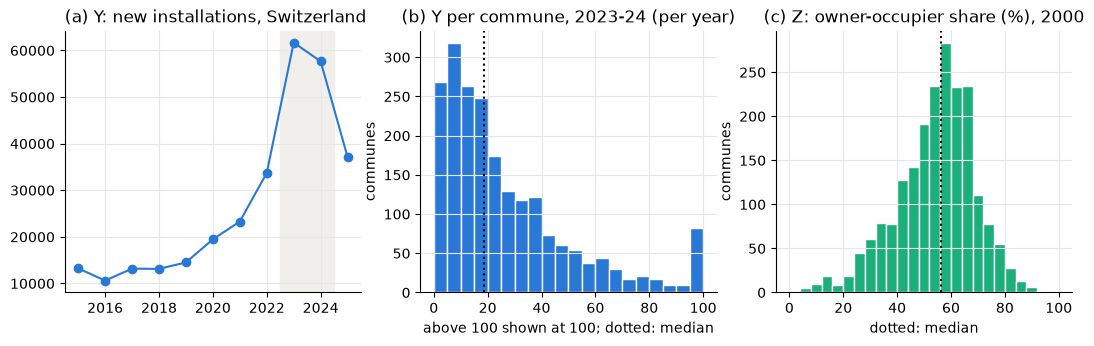

In [21]:
per_year = installs.groupby("year").n_new.sum()
print(f"installations 2021 -> 2023: {per_year[2021]:,} -> {per_year[2023]:,} ({per_year[2023] / per_year[2021] - 1:+.0%})")

fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
axs[0].plot(per_year.index, per_year, marker="o", color=BLUE)
axs[0].axvspan(2022.5, 2024.5, color="#f0efec", zorder=0)               # shaded: 2023-24
axs[0].set_title("(a) Y: new installations, Switzerland", loc="left")
axs[1].hist(communes.n_post.clip(upper=100), bins=range(0, 105, 5), color=BLUE, edgecolor="white")
axs[1].axvline(communes.n_post.median(), color="black", ls=":")
axs[1].set(title="(b) Y per commune, 2023-24 (per year)", xlabel="above 100 shown at 100; dotted: median", ylabel="communes")
axs[2].hist(communes.owner_share_2000 * 100, bins=range(0, 101, 4), color=GREEN, edgecolor="white")
axs[2].axvline(communes.owner_share_2000.median() * 100, color="black", ls=":")
axs[2].set(title="(c) Z: owner-occupier share (%), 2000", xlabel="dotted: median", ylabel="communes")
plt.show()

Across space: where did installations grow, and where do owners live? Each map colours communes by class; grey = no data.

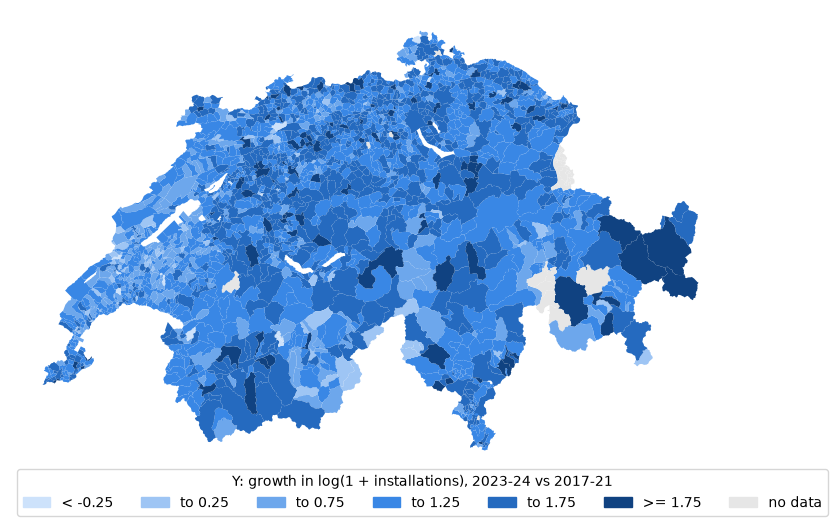

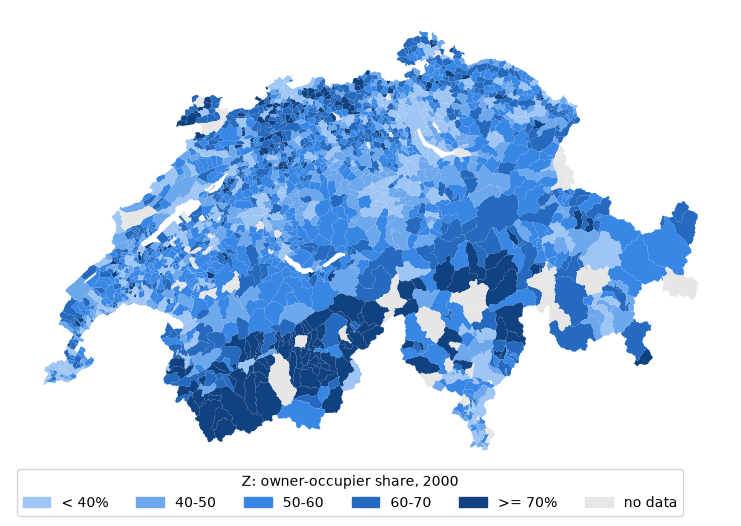

In [23]:
def draw_map(values, edges, labels, title):
    """Colour each commune by the class of its value (edges = class limits); borders simplified to draw faster."""
    colours = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#104281"][-len(labels):]
    fig, ax = plt.subplots(figsize=(10, 6))
    for bfs, geom in polygons.items():
        value = values.get(bfs)
        colour = "#e6e6e6" if pd.isna(value) else colours[np.digitize(value, edges)]
        for part in get_parts(geom.simplify(0.001)):
            ax.fill(*part.exterior.xy, color=colour, linewidth=0)
    ax.set_aspect(1.46); ax.axis("off")                                  # 1.46 = 1 / cos(latitude of Switzerland)
    ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in colours + ["#e6e6e6"]], labels + ["no data"],
              title=title, ncol=len(labels) + 1, loc="upper left", bbox_to_anchor=(0, 0.02))
    plt.show()

draw_map(communes.growth, [-0.25, 0.25, 0.75, 1.25, 1.75], ["< -0.25", "to 0.25", "to 0.75", "to 1.25", "to 1.75", ">= 1.75"],
         "Y: growth in log(1 + installations), 2023-24 vs 2017-21")
draw_map(communes.owner_share_2000, [0.4, 0.5, 0.6, 0.7], ["< 40%", "40-50", "50-60", "60-70", ">= 70%"], "Z: owner-occupier share, 2000")

### X, the 2023 tariff increase (slides 2 and 11)
Nature: **continuous** (ct/kWh). No log: some communes had a small decrease. The 17 communes above 25 ct are real (small local utilities): we keep them rather than deleting outliers.

In [25]:
print(communes.shock23.describe().round(2))
print(f"median increase relative to the 2022 tariff: {(communes.shock23 / communes.t2022).median():+.0%}")      # slide 2
print(f"energy part of the increase (averages): {communes.shock_energy23.mean() / communes.shock23.mean():.0%}")
within = communes.shock23 - communes.groupby("canton").shock23.transform("mean")   # remove each canton's average
print(f"share of the variance within cantons: {within.var() / communes.shock23.var():.0%}")
print("communes above 25 ct:", (communes.shock23 > 25).sum())

count    2098.00
mean        6.58
std         5.01
min        -0.47
25%         3.80
50%         5.06
75%         9.85
max        43.00
Name: shock23, dtype: float64
median increase relative to the 2022 tariff: +28%
energy part of the increase (averages): 87%
share of the variance within cantons: 74%
communes above 25 ct: 17


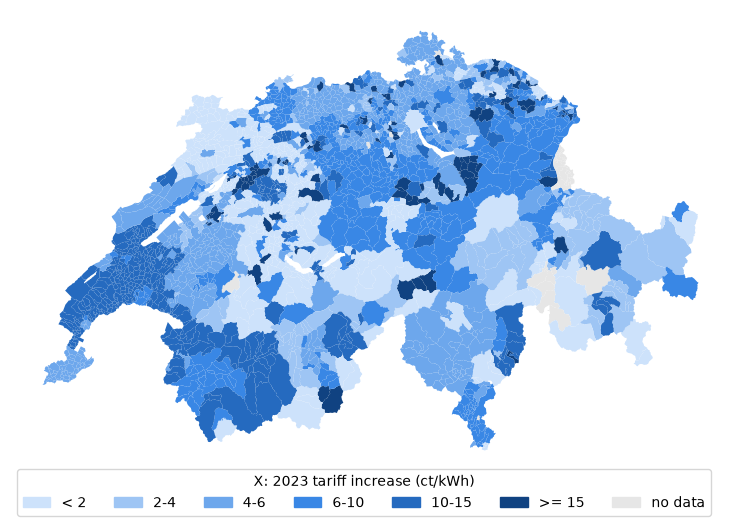

In [26]:
draw_map(communes.shock23, [2, 4, 6, 10, 15], ["< 2", "2-4", "4-6", "6-10", "10-15", ">= 15"], "X: 2023 tariff increase (ct/kWh)")

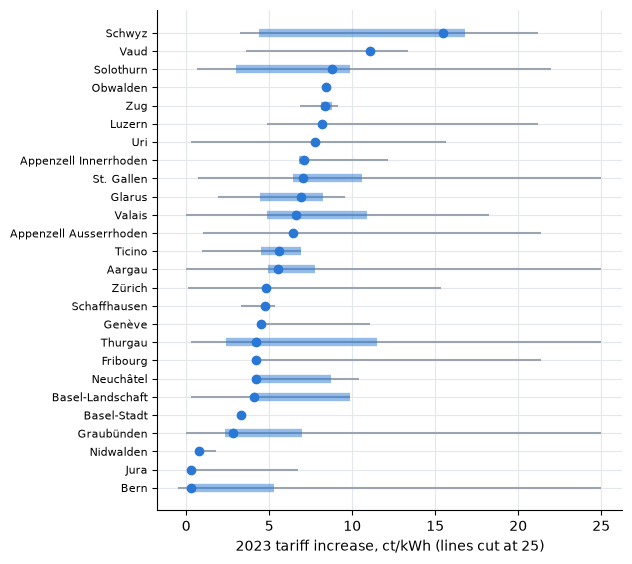

In [27]:
# spread inside each canton: line = min to max, thick bar = middle 50%, dot = median
stats = communes.groupby("canton").shock23.describe().sort_values("50%")
rows = range(len(stats))
fig, ax = plt.subplots(figsize=(6, 6.5))
ax.hlines(rows, stats["min"], stats["max"].clip(upper=25), color=GREY)
ax.hlines(rows, stats["25%"], stats["75%"], color=BLUE, lw=6, alpha=.5)
ax.plot(stats["50%"], rows, "o", color=BLUE)
ax.set_yticks(rows, [name.split(" / ")[0] for name in stats.index], fontsize=8)
ax.set_xlabel("2023 tariff increase, ct/kWh (lines cut at 25)")
plt.show()

## 4. Bivariate analysis

### Thirds of the shock (slide 12)
Split communes into three groups of about equal size by X (communes with the same value stay together) and follow Y over time. Y is **summed over the communes of each group** (so big communes weigh more) and **indexed to 2021 = 100**, because the groups differ in size.

mean increase by third: {'low': 2.0, 'middle': 5.9, 'high': 12.3}


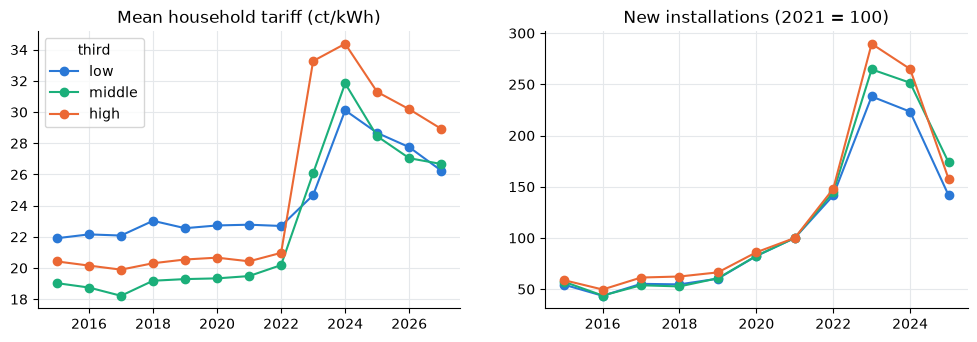

2023 index: {'low': 238.0, 'middle': 265.0, 'high': 290.0}
tariff gap high - low: 8.6 ct (2023) -> 4.3 ct (2024)
tariff change 2023 -> 2024: {'low': 5.4, 'middle': 5.8, 'high': 1.1}


In [29]:
communes["third"] = pd.qcut(communes.shock23, 3, labels=["low", "middle", "high"])
print("mean increase by third:", communes.groupby("third", observed=True).shock23.mean().round(1).to_dict())

tariff_by_third = tariff.groupby(communes.third, observed=True).mean().T
counts = installs.join(communes.third, on="bfs").groupby(["year", "third"], observed=True).n_new.sum().unstack()
index = counts / counts.loc[2021] * 100

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
tariff_by_third.plot(ax=axs[0], marker="o", color=[BLUE, GREEN, ORANGE], title="Mean household tariff (ct/kWh)", xlabel="")
index.plot(ax=axs[1], marker="o", color=[BLUE, GREEN, ORANGE], title="New installations (2021 = 100)", legend=False, xlabel="")
plt.show()

print("2023 index:", index.loc[2023].round().to_dict())
gap = tariff_by_third["high"] - tariff_by_third["low"]
print(f"tariff gap high - low: {gap[2023]:.1f} ct (2023) -> {gap[2024]:.1f} ct (2024)")
print("tariff change 2023 -> 2024:", (tariff_by_third.loc[2024] - tariff_by_third.loc[2023]).round(1).to_dict())   # the others partly caught up

Before 2022 the lines move roughly together; in 2023 the high-shock third grows most; in 2024 the other thirds partly catch up on tariffs (the gap halves), and by 2025 the gap in installations narrows.

### Commune by commune (slide 13)
X stays continuous; Y is the growth defined in section 2.
To compare like with like we remove the canton average from X and from growth (cantons have their own rules and subsidies), then fit a straight line.

slope: 0.24 log points of growth per +10 ct/kWh, within cantons


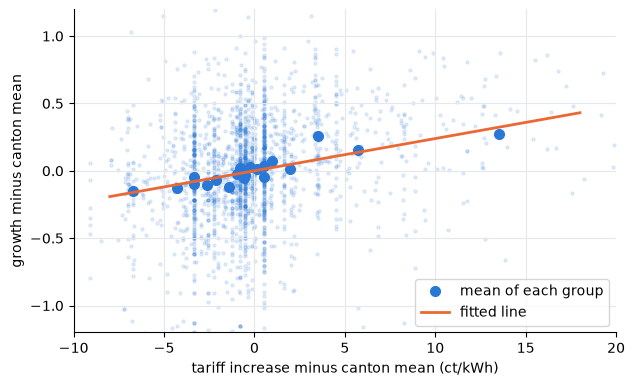

In [31]:
x = communes.shock23 - communes.groupby("canton").shock23.transform("mean")
y = communes.growth - communes.groupby("canton").growth.transform("mean")

slope = np.polyfit(x, y, 1)[0]                                            # straight-line fit
print(f"slope: {slope * 10:.2f} log points of growth per +10 ct/kWh, within cantons")

groups = pd.qcut(x.rank(method="first"), 20, labels=False)               # 20 equal-size groups of communes by x
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(x, y, s=5, alpha=.12, color=BLUE)
ax.plot(x.groupby(groups).mean(), y.groupby(groups).mean(), "o", color=BLUE, ms=7, label="mean of each group")
ax.plot([-8, 18], [-8 * slope, 18 * slope], color=ORANGE, lw=2, label="fitted line")
ax.set(xlim=(-10, 20), ylim=(-1.2, 1.2), xlabel="tariff increase minus canton mean (ct/kWh)", ylabel="growth minus canton mean")
ax.legend(); plt.show()

**Check before the shock, and how precise the slopes are (slide 13).** The same slope computed on growth from 2017–18 to 2020–21 (before anyone knew about 2023) should be about zero. For a 95% confidence interval we fit the same straight line with a standard regression, allowing communes served by the same operator to share their errors (they got the same shock).

In [33]:
before = installs[installs.year.isin([2020, 2021])].groupby("bfs").n_new.mean()
earlier = installs[installs.year.isin([2017, 2018])].groupby("bfs").n_new.mean()
placebo = np.log1p(before) - np.log1p(earlier)
y_placebo = placebo - placebo.groupby(communes.canton).transform("mean")

for name, outcome in [("after the shock (2023-24)", y), ("before the shock (2020-21)", y_placebo)]:
    fit = sm.OLS(outcome, sm.add_constant(x / 10)).fit(cov_type="cluster", cov_kwds={"groups": communes.operator})
    low, high = fit.conf_int().loc["shock23"]
    print(f"{name}: slope {fit.params['shock23']:.2f}, 95% CI {low:.2f} to {high:.2f}")

after the shock (2023-24): slope 0.24, 95% CI 0.20 to 0.28
before the shock (2020-21): slope 0.02, 95% CI -0.03 to 0.07


### Adding Z (slide 14)
The same thirds, separately below and above the median owner-occupier share (56%). Descriptive only: Z also moves with house type and commune size (next table).

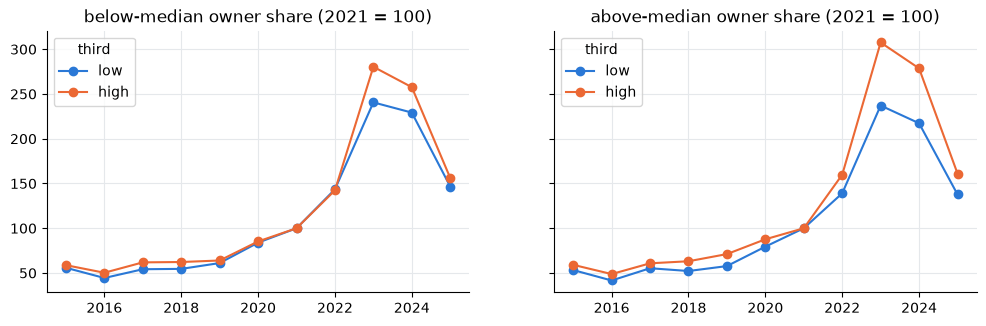

third,low,high
z_group,,
below,241.0,280.0
above,237.0,308.0


In [35]:
median = communes.owner_share_2000.median()
communes["z_group"] = pd.cut(communes.owner_share_2000, [0, median, 1], right=False, labels=["below", "above"])
counts = installs.join(communes[["third", "z_group"]], on="bfs").groupby(["year", "z_group", "third"], observed=True).n_new.sum()
index_z = (counts / counts.xs(2021, level="year") * 100).unstack(["z_group", "third"])

fig, axs = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, group in zip(axs, ["below", "above"]):
    index_z[group][["low", "high"]].plot(ax=ax, marker="o", color=[BLUE, ORANGE], title=f"{group}-median owner share (2021 = 100)", xlabel="")
plt.show()
index_z.loc[2023].unstack()[["low", "high"]].round()                   # 2023 index, high vs low shock

### What else moves with X, Y and Z? (backup slide; numbers on slides 10, 14 and 16)

In [37]:
communes["log_pop"] = np.log(communes.pop_2021)
names = {"shock23": "X: shock", "growth": "Y: growth", "owner_share_2000": "Z: owner share", "t2022": "tariff 2022",
         "sfh_share_2021": "single-family share", "pv_stock21_pc": "PV per 1,000 inh. 2021", "log_pop": "log population"}
communes[list(names)].rename(columns=names).corr()[["X: shock", "Y: growth", "Z: owner share"]].round(2)

,X: shock,Y: growth,Z: owner share
X: shock,1.00,0.14,-0.05
Y: growth,0.14,1.00,-0.13
Z: owner share,-0.05,-0.13,1.00
tariff 2022,-0.26,-0.07,-0.00
single-family share,0.05,0.08,0.41
"PV per 1,000 inh. 2021",0.03,-0.47,0.40
log population,0.08,0.43,-0.62


## 5. Causality issues (slides 15 and 16)

**Is there something else?** The shock was chosen by operators, not random. The same operator also sets the **feed-in tariff** (what it pays for solar power sent to the grid). Feed-in tariffs come from VESE ([pvtarif](https://www.pvtarif.ch), licensed, team use only): remuneration = energy + guarantee of origin, for small plants. We compare 2021 with 2023, because 2022 values of operators paying the quarterly market price are one-quarter snapshots.

*Données des tarifs de rétribution: VESE / pvtarif.ch (http://www.vese.ch, http://www.pvtarif.ch).*

In [39]:
print(communes.groupby("regional_utility").shock23.mean().round(1))      # True = operator serving 10+ communes

def feed_in(year):
    with open(f"data/vese_pvtarif_{year}.json", encoding="utf-8") as f:
        vese = pd.DataFrame.from_dict(json.load(f), orient="index")       # one row per operator
    energy = pd.to_numeric(vese.energy1, errors="coerce")
    origin = pd.to_numeric(vese.eco1, errors="coerce").fillna(0).where(vese.ecoIncl != "y", 0)   # unless already included
    return (energy + origin).where(energy > 0).rename(int)               # 0 = missing entry

feedin_change = communes.operator.map(feed_in(2023)) - communes.operator.map(feed_in(2021))
ok = feedin_change.notna()
print(f"X vs feed-in change 2021->2023: r = {communes.shock23[ok].corr(feedin_change[ok]):.2f} ({ok.sum():,} communes)")

regional_utility
False    8.5
True     5.8
Name: shock23, dtype: float64
X vs feed-in change 2021->2023: r = 0.79 (1,994 communes)


- **Operators chose the shock.** Regional utilities (serving 10+ communes) and communes with high 2022 tariffs (r = −0.26, section 4) got **smaller** increases.
- **Feed-in moved too.** The feed-in tariff moved with X (r = 0.79): two possible explanations to separate.
- **Everyone was treated.** Every commune saw the crisis, and the low-shock communes partly caught up in 2024 (the tariff gap halved, section 4), so we see a short-run difference between communes.
- **Local policy and supply.** Communal subsidies and installer queues may differ between communes; we do not observe them yet.
- **Timing.** Above the median owner share, the high-shock third already led in 2022 (section 4): possible anticipation, since the 2023 tariffs were known from August 2022.

**Is it the reverse?** Unlikely: 2023 tariffs were published by the end of August 2022, before the installations we count. More solar could raise grid fees, but 87% of the increase was the energy part (section 3), and X is unrelated to the PV a commune already had (r = 0.03).

**Can we extrapolate?** Only with care: one crisis year with heavy media attention; commune averages, not individual owners (Z is a commune share); Y counts all plants (12% of them above 30 kW: farms, firms); sample bias: 12 communes without a 2022 tariff are dropped (8 in Graubünden) and Z is missing for 35.

**Plan for the final:** compare communes within cantons over time with a regression, test for pre-trends and anticipation, compare neighbouring communes with different operators, use Z as a continuous variable, and try to separate the retail from the feed-in change.